In [1]:
# from ucimlrepo import fetch_ucirepo
# import pandas as pd

# cdc = fetch_ucirepo(id=891)
# df = pd.concat([cdc.data.features, cdc.data.targets], axis=1)
# df.to_csv("../data/diabetes_cdc.csv", index=False)

# print(df.shape)
# df.head()

In [4]:
import pandas as pd
pd.set_option("display.max_columns", None)   # show all 22 columns instead of cutting them off
df = pd.read_csv("../data/diabetes_cdc.csv")

df.shape

(253680, 22)

In [5]:
df.isnull().sum().sum()

np.int64(0)

In [6]:
df.duplicated().sum()

np.int64(24206)

In [5]:
df.columns            # lists all 22 column names; Diabetes_binary is last

Index(['HighBP', 'HighChol', 'CholCheck', 'BMI', 'Smoker', 'Stroke',
       'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies',
       'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'GenHlth',
       'MentHlth', 'PhysHlth', 'DiffWalk', 'Sex', 'Age', 'Education', 'Income',
       'Diabetes_binary'],
      dtype='str')

In [7]:
df["Diabetes_binary"].value_counts(normalize=True)

Diabetes_binary
0    0.860667
1    0.139333
Name: proportion, dtype: float64

In [8]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
HighBP,253680.0,0.429001,0.494934,0.0,0.0,0.0,1.0,1.0
HighChol,253680.0,0.424121,0.494210,0.0,0.0,0.0,1.0,1.0
CholCheck,253680.0,0.962670,0.189571,0.0,1.0,1.0,1.0,1.0
BMI,253680.0,28.382364,6.608694,12.0,24.0,27.0,31.0,98.0
Smoker,253680.0,0.443169,0.496761,0.0,0.0,0.0,1.0,1.0
Stroke,253680.0,0.040571,0.197294,0.0,0.0,0.0,0.0,1.0
HeartDiseaseorAttack,253680.0,0.094186,0.292087,0.0,0.0,0.0,0.0,1.0
PhysActivity,253680.0,0.756544,0.429169,0.0,1.0,1.0,1.0,1.0
Fruits,253680.0,0.634256,0.481639,0.0,0.0,1.0,1.0,1.0
Veggies,253680.0,0.811420,0.391175,0.0,1.0,1.0,1.0,1.0


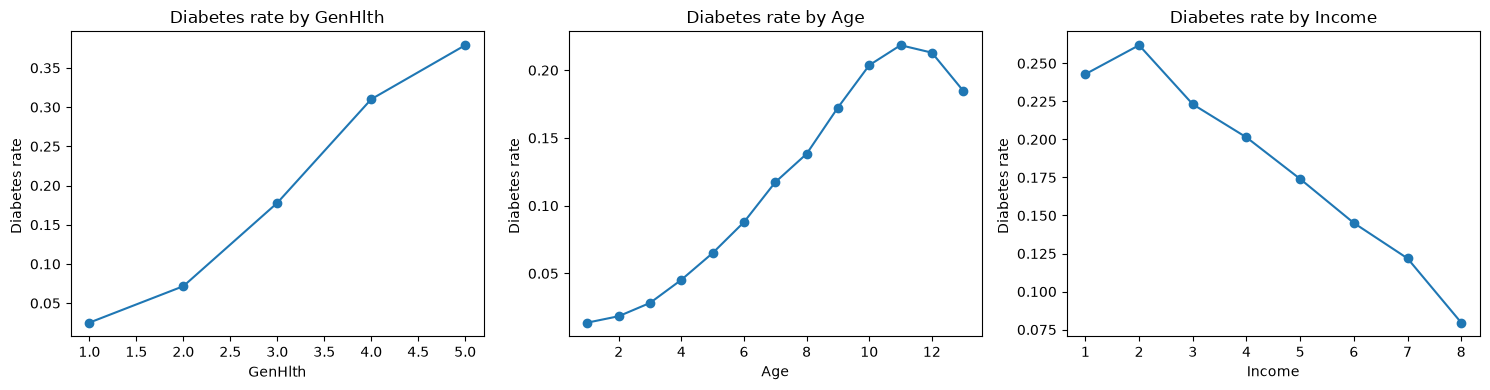

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["GenHlth","Age","Income"]):
    df.groupby(col)["Diabetes_binary"].mean().plot(marker="o", ax=ax)
    ax.set_title(f"Diabetes rate by {col}")
    ax.set_ylabel("Diabetes rate ")

plt.tight_layout()
plt.show()

Self-rated health: diabetes rate rises from 2.5% (excellent) to 37.9% (poor), about 15x higher.

Age: rises from 1.4% (ages 18-24) to a peak of 21.8% (ages 70-74), then dips to 18.5% (80+). The dip is likely a survivor effect.

Income: falls from about 26% (under $15k) to 8% ($75k+), about 3x lower. Income likely reflects access to healthy food and healthcare, not a direct cause.

In [21]:
for col in ["GenHlth", "Age", "Income"]:
    print(df.groupby(col)["Diabetes_binary"].mean().round(3), "\n")

GenHlth
1    0.025
2    0.072
3    0.178
4    0.310
5    0.379
Name: Diabetes_binary, dtype: float64 

Age
1     0.014
2     0.018
3     0.028
4     0.045
5     0.065
6     0.088
7     0.117
8     0.138
9     0.172
10    0.204
11    0.218
12    0.213
13    0.185
Name: Diabetes_binary, dtype: float64 

Income
1    0.243
2    0.262
3    0.223
4    0.201
5    0.174
6    0.145
7    0.122
8    0.080
Name: Diabetes_binary, dtype: float64 



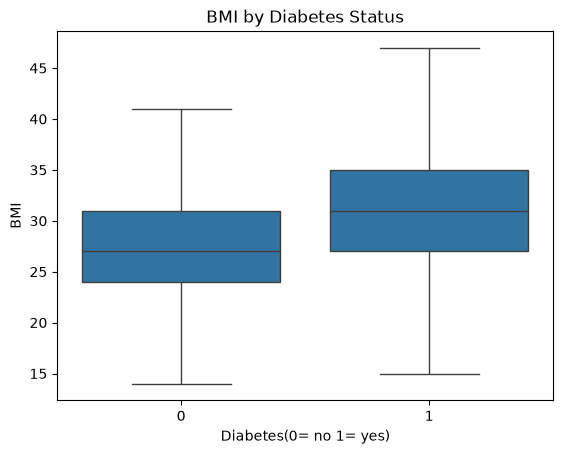

In [24]:
sns.boxplot(data=df, x= "Diabetes_binary", y="BMI", showfliers = False)
plt.title("BMI by Diabetes Status")
plt.xlabel("Diabetes(0= no 1= yes)")
plt.show()

BMI: median is 27 without diabetes and 31 with diabetes. The diabetes group has higher BMI, but the two groups overlap a lot, so BMI alone can't predict diabetes.

In [20]:
df.groupby("Diabetes_binary")["BMI"].describe().round(1)

,count,mean,std,min,25%,50%,75%,max
Diabetes_binary,,,,,,,,
0,218334.0,27.8,6.3,12.0,24.0,27.0,31.0,98.0
1,35346.0,31.9,7.4,13.0,27.0,31.0,35.0,98.0


In [10]:
import matplotlib.pyplot as plt
import seaborn as sns
binary_cols = ["HighBP", "HighChol", "Smoker", "Stroke", "HeartDiseaseorAttack",
               "PhysActivity", "Fruits", "Veggies", "HvyAlcoholConsump", "DiffWalk"]
rates = pd.DataFrame({
    "rate_if_no": [df[df[c] == 0]["Diabetes_binary"].mean() for c in binary_cols],
    "rate_if_yes": [df[df[c] == 1]["Diabetes_binary"].mean() for c in binary_cols],
},index = binary_cols)
rates["difference"] = rates["rate_if_yes"] - rates["rate_if_no"]
rates.sort_values("difference", ascending = False)


,rate_if_no,rate_if_yes,difference
HeartDiseaseorAttack,0.119537,0.329720,0.210183
DiffWalk,0.105329,0.307463,0.202134
Stroke,0.131798,0.317528,0.185730
HighBP,0.060352,0.244457,0.184105
HighChol,0.079814,0.220149,0.140334
Smoker,0.120553,0.162929,0.042376
Fruits,0.157929,0.128609,-0.029320
Veggies,0.179979,0.129887,-0.050092
HvyAlcoholConsump,0.144154,0.058361,-0.085793
PhysActivity,0.211448,0.116127,-0.095321


Yes/no features vs. diabetes:
- Strongest risk signals: heart disease (33% vs 12%), difficulty walking (31% vs 11%), stroke (32% vs 13%), high blood pressure (24% vs 6%), high cholesterol (22% vs 8%).
- High blood pressure has the largest ratio: 4x the diabetes rate.
- Smoking, fruits and veggies show only small differences.
- Physical activity is linked to lower diabetes (12% vs 21%).
- Heavy drinking appears linked to lower diabetes (6% vs 14%). This is likely reverse causation or confounding by age, not a real protective effect. Correlation is not causation.